# EMQA_L3_tails

**Density (log scale) of the GARCH(1,1)-t standardised daily shocks of the Romanian base price, 2019-01-01 to 2026-10-31, against the normal and the fitted Student-t density: extreme days are far more frequent than the normal law allows (fat tails).**

Energy Markets Quantitative Analysis (EMQA), Lecture 3 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L3/EMQA_L3_tails/EMQA_L3_tails.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
C_PCT, C_EUR = PAL['RO'], PAL['c7']          # percent changes, EUR/MWh changes


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    # legend centred under the axes, outside the plotting area
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def slide(label, key, x, k=None):
    # prints a number shown on the slide; [key] = its name in lectures/L3/L3_numbers.json
    if k is not None:
        x = round(float(x), k)
    print(f'{label:<58s} {x}   [{key}]')

## Fat tails

GARCH(1,1) with Student-$t$ shocks on the percent shocks $\varepsilon_t$: $\varepsilon_t=\sigma_t z_t$, $\sigma_t^2=\omega+\alpha\varepsilon_{t-1}^2+\beta\sigma_{t-1}^2$. The histogram shows the standardised shocks $z_t=\varepsilon_t/\hat\sigma_t$.

In [3]:
# Romanian daily base price (mean of all MTUs of the CET/CEST delivery day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month; panel from 2019-01-01, on the full calendar
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp('2019-01-01')
CAL = pd.date_range(START, END, freq='D')
P = PD['RO'].reindex(CAL)
print('Romania, daily base price:', START.date(), 'to', END.date(), '|', len(CAL), 'days, missing:', int(P.isna().sum()))

Romania, daily base price: 2019-01-01 to 2026-10-31 | 2861 days, missing: 0


In [4]:
# daily changes on the full calendar: percent (log) and EUR/MWh
r = 100 * np.log(P.where(P > 0)).diff()      # r_t = 100 ln(P_t / P_{t-1}); missing if a price is <= 0
u = P.diff()                                  # Delta P_t = P_t - P_{t-1}, EUR/MWh

In [5]:
import statsmodels.api as sm


def mean_design(y, lags=7):
    # constant + AR(1..7) + six day-of-week dummies (Monday = base)
    X = pd.DataFrame({f'L{k}': y.shift(k) for k in range(1, lags + 1)}, index=y.index)
    for j in range(1, 7):
        X[f'D{j}'] = (y.index.dayofweek == j).astype(float)
    X.insert(0, 'const', 1.0)
    return X


def mean_fit(y, lags=7):
    # OLS mean equation; returns (residuals = shocks, fitted model)
    X = mean_design(y, lags)
    df = pd.concat([y.rename('y'), X], axis=1).dropna()
    m = sm.OLS(df['y'], df.drop(columns='y')).fit()
    return m.resid, m


E_PCT, M_PCT = mean_fit(r)       # shocks epsilon_t, percent
print('shocks:', E_PCT.index[0].date(), 'to', E_PCT.index[-1].date(), '|', len(E_PCT), 'days')

shocks: 2019-01-09 to 2026-10-31 | 2853 days


In [6]:
try:
    import arch
except ImportError:          # Google Colab: install the arch package once
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'arch'])
from arch import arch_model


def fit(e, vol='GARCH', o=0, dist='t'):
    # zero-mean GARCH(1,1) (o=0) or GJR-GARCH(1,1,1) (o=1), Student-t shocks by default
    return arch_model(np.asarray(e, float), mean='Zero', vol=vol, p=1, o=o, q=1, dist=dist,
                      rescale=False).fit(disp='off', show_warning=False)

### Numbers on the slide

In [7]:
from scipy import stats
res = fit(E_PCT)
nu = round(float(res.params['nu']), 4)
z = (E_PCT - E_PCT.mean()) / E_PCT.std()
slide('excess kurtosis of the shocks', 'facts.kurt', E_PCT.kurt(), 2)
slide('skewness of the shocks', 'facts.skew', E_PCT.skew(), 2)
slide('shocks beyond 4 standard deviations', 'facts.n_4sd', int((z.abs() > 4).sum()))
slide('  expected under normality', 'facts.n_4sd_norm', len(z) * 2 * stats.norm.sf(4), 2)
slide('Student-t degrees of freedom nu', 'garch.pct.garch_t.nu', nu)

excess kurtosis of the shocks                              20.01   [facts.kurt]
skewness of the shocks                                     -1.69   [facts.skew]
shocks beyond 4 standard deviations                        15   [facts.n_4sd]
  expected under normality                                 0.18   [facts.n_4sd_norm]
Student-t degrees of freedom nu                            4.2656   [garch.pct.garch_t.nu]


### Chart

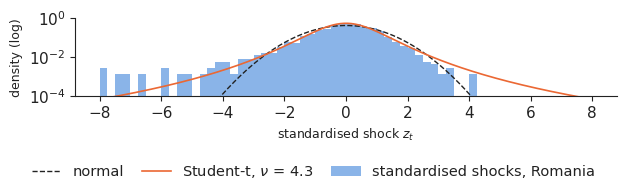

In [8]:
zz = res.std_resid
fig, ax = plt.subplots(figsize=(6.4, 2.0))
bins = np.linspace(-8, 8, 65)
hcount, edges = np.histogram(np.clip(zz, -8, 8), bins=bins, density=True)
ax.bar(0.5 * (edges[1:] + edges[:-1]), hcount, width=edges[1] - edges[0], color=C_PCT, alpha=0.55, lw=0,
       label='standardised shocks, Romania')
xs = np.linspace(-8, 8, 400)
ax.plot(xs, stats.norm.pdf(xs), color='#222222', lw=1.0, ls='--', label='normal')
sc = np.sqrt((nu - 2) / nu)          # unit-variance Student-t
ax.plot(xs, stats.t.pdf(xs / sc, nu) / sc, color=PAL['DE_LU'], lw=1.2, label=f'Student-t, $\\nu$ = {nu:.1f}')
ax.set_yscale('log')
ax.set_ylim(1e-4, 1)
ax.set_xlabel('standardised shock $z_t$', fontsize=9)
ax.set_ylabel('density (log)', fontsize=9)
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.17, 1, 1))
plt.savefig('tails.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()